In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from keras._tf_keras.keras.applications import ResNet50
from keras._tf_keras.keras.models import Model
from keras._tf_keras.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from keras._tf_keras.keras.optimizers import AdamW
from keras._tf_keras.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
from keras._tf_keras.keras.optimizers import AdamW

In [20]:
# Paths to balanced dataset
data_dir = r"C:\Users\Legion\Desktop\pneumo\data\balanced"

In [21]:
# Model Parameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10 #Change epochs as needed

In [22]:
# Data Augmentation for Dynamic Augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2
)
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255)

In [23]:
# Data Generators
train_generator = train_datagen.flow_from_directory(
    os.path.join(data_dir, 'train'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)
val_generator = val_test_datagen.flow_from_directory(
    os.path.join(data_dir, 'val'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)
test_generator = val_test_datagen.flow_from_directory(
    os.path.join(data_dir, 'test'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 5982 images belonging to 2 classes.
Found 1282 images belonging to 2 classes.
Found 1282 images belonging to 2 classes.


In [24]:
# Load ResNet50 Model
base_model = ResNet50(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

In [25]:
# Freeze the base layers
for layer in base_model.layers[:-10]:
    layer.trainable = False

In [26]:
# Add custom layers
global_avg_pooling = GlobalAveragePooling2D()(base_model.output)
dropout_layer = Dropout(0.3)(global_avg_pooling)
prediction_layer = Dense(len(train_generator.class_indices), activation='softmax')(dropout_layer)

In [27]:
# Compile Model
model = Model(inputs=base_model.input, outputs=prediction_layer)
optimizer = AdamW(learning_rate=1e-4, weight_decay=1e-4)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_pad (ZeroPadding2D)     │ (None, 230, 230, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_conv (Conv2D)           │ (None, 112, 112, 64)      │           9,472 │ conv1_pad[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_bn (BatchNormalization) │ (None, 112, 112, 64)      │             256 │ conv1_conv[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_relu (Activation)       │ (None, 112, 112, 64)      │               0 │ conv1_bn[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1_pad (ZeroPadding2D)     │ (None, 114, 114, 64)      │               0 │ conv1_relu[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1_pool (MaxPooling2D)     │ (None, 56, 56, 64)        │               0 │ pool1_pad[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_conv (Conv2D)  │ (None, 56, 56, 64)        │           4,160 │ pool1_pool[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_bn             │ (None, 56, 56, 64)        │             256 │ conv2_block1_1_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_1_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_conv (Conv2D)  │ (None, 56, 56, 64)        │          36,928 │ conv2_block1_1_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_bn             │ (None, 56, 56, 64)        │             256 │ conv2_block1_2_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_2_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_conv (Conv2D)  │ (None, 56, 56, 256)       │          16,640 │ pool1_pool[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_3_conv (Conv2D)  │ (None, 56, 56, 256)       │          16,640 │ conv2_block1_2_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 23,591,810 (90.00 MB)

 Trainable params: 4,469,762 (17.05 MB)

 Non-trainable params: 19,122,048 (72.94 MB)

In [28]:
# Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

In [29]:
# Train Model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    steps_per_epoch=len(train_generator),
    validation_steps=len(val_generator),
    callbacks=callbacks
)

C:\Users\Legion\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
187/187 ━━━━━━━━━━━━━━━━━━━━ 254s 1s/step - accuracy: 0.8095 - loss: 0.3892 - val_accuracy: 0.8198 - val_loss: 0.3825 - learning_rate: 1.0000e-04
Epoch 2/10
187/187 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 0.8852 - loss: 0.2636 - val_accuracy: 0.7816 - val_loss: 0.5489 - learning_rate: 1.0000e-04
Epoch 3/10
187/187 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 0.8938 - loss: 0.2451 - val_accuracy: 0.9150 - val_loss: 0.2029 - learning_rate: 1.0000e-04
Epoch 4/10
187/187 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 0.8918 - loss: 0.2415 - val_accuracy: 0.5055 - val_loss: 3.5287 - learning_rate: 1.0000e-04
Epoch 5/10
187/187 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 0.9034 - loss: 0.2319 - val_accuracy: 0.9103 - val_loss: 0.2456 - learning_rate: 1.0000e-04
Epoch 6/10
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9067 - loss: 0.2228
Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
187/187 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 

In [30]:
# Evaluate Model
print("Evaluating model on test set...")
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test Accuracy: {test_accuracy:.2f}")

Evaluating model on test set...
41/41 ━━━━━━━━━━━━━━━━━━━━ 37s 890ms/step - accuracy: 0.8995 - loss: 0.2390
Test Accuracy: 0.93


In [31]:
# Classification Report and Confusion Matrix
y_pred = model.predict(test_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_generator.classes

print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=list(test_generator.class_indices.keys())))

41/41 ━━━━━━━━━━━━━━━━━━━━ 39s 920ms/step
Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.96      0.89      0.92       645
   PNEUMONIA       0.90      0.96      0.93       637

    accuracy                           0.93      1282
   macro avg       0.93      0.93      0.93      1282
weighted avg       0.93      0.93      0.93      1282



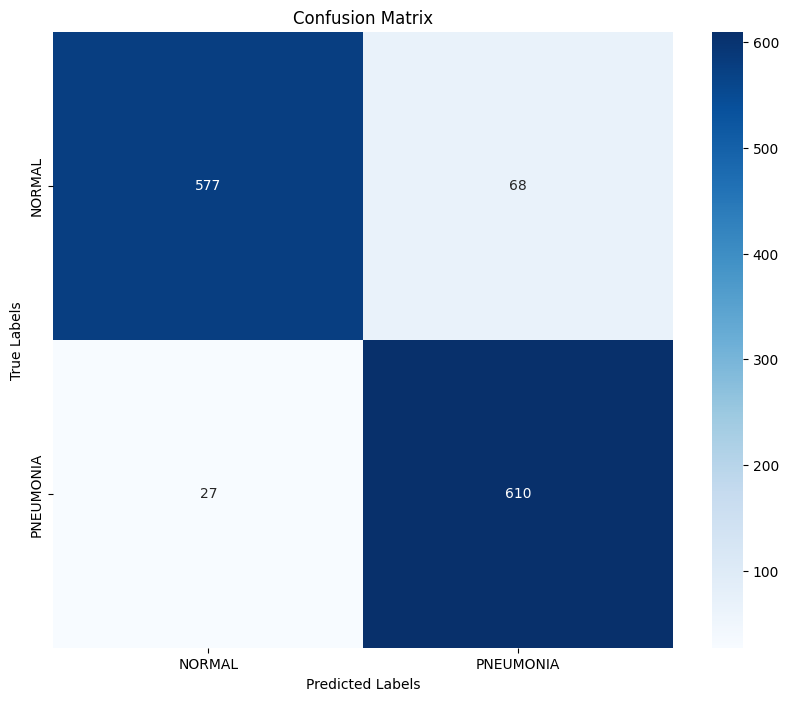

In [32]:
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [33]:
# Save Model
model.save(r'C:\Users\Legion\Desktop\pneumo\resnet50\model\ResNet50_Pneumo1.keras')
print("Model saved as 'ResNet50_Pneumo.keras'")

Model saved as 'ResNet50_Pneumo.keras'


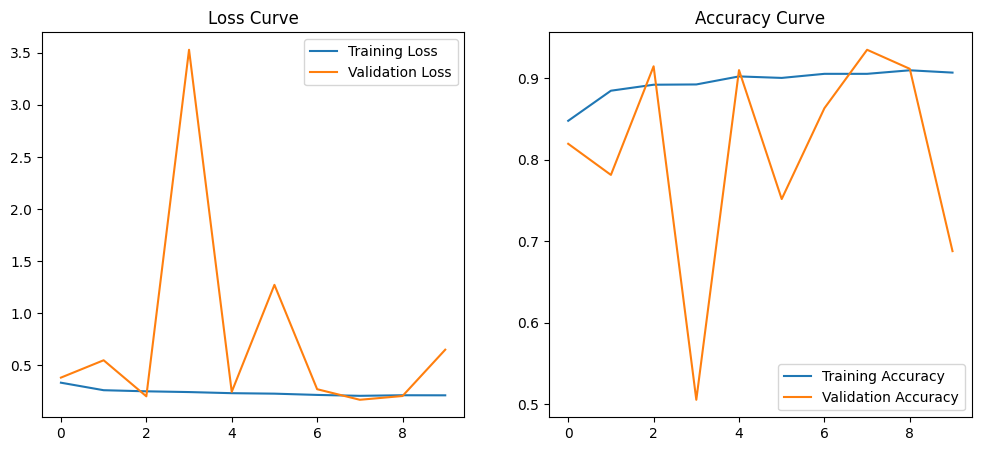

In [34]:
# Plot Training History
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.show()